In [1]:
from II_funcs import *
import corner
import re
from interp_funcs import *
plt.rcParams['mathtext.fontset'] =  "cm"
plt.rcParams['font.family'] =  "serif"
plt.rcParams['mathtext.default']='regular'

from IPython.display import FileLink
import gc
from scipy.interpolate import RectBivariateSpline
gc.collect()
theta_E_4 = np.array([np.sqrt(4 * G * .4*(2e33) / c**2 * D_ls / (D_s * D_l))])
theta_E_8 = np.array([np.sqrt(4 * G * .8*(2e33) / c**2 * D_ls / (D_s * D_l))])

data=np.load('data/macro_lens_results.npz')
mag_fit=6.86
phi_0=-2.07858699980682
B_matrix=data['inv_jacobian_fit'][0]
from scipy.interpolate import RegularGridInterpolator
from scipy.stats import linregress


In [2]:
from matplotlib import rc
from matplotlib import rcParams

rcParams['font.family'] = 'serif'
rc('text', usetex=True)
custom_preamble = {
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}"
    }
plt.rcParams.update(custom_preamble)


In [3]:
import os
os.environ["PATH"] += ":/mnt/sw/nix/store/2h2mfxgy98zls6ja0czcz087i38v8wx3-texlive-20240312/bin/x86_64-linux"

from matplotlib import rc
rc("text", usetex=True)

In [4]:
#define image specific constants, these don't change within this file
theta_max = 2e-10 # (half) size of image
image_size=8000
N_step = image_size
beta_min = .9e-11
g_params = (kappa_bulk, gamma1, gamma2)
# Fiducial source radius: use the corrected II_funcs.theta_500 (16pi/3 flux
# normalization -> 1.9584e-13 rad, lambda=570 nm), matching the freshly regenerated
# data/ grids.
rad = theta_500
rad_mas=rad*rad_to_arcsec
# sigma_C exactly as used by run_II_fisher.py used by run_II_fisher.py: image A flux
# (m=15.76 with a 2635 Jy zero point) at 570 nm, R=2e4, sigma_t=3 ps,
# A = 10 x pi x (5 m)^2 = 785 m^2 total, eta1=eta2=0.5, t_obs = 8 h  ->  4.66.
# (An earlier version of this cell used mag=16.5 at 500 nm, giving 9.21 -- NOT what
# the data used.)
sigma_C = error_C(mag=15.76, wavelength=570e-7, R = 2e4, sigma_t=3e-12, A=10*(500**2)*np.pi, t_obs= 8 * 3600)
print(sigma_C)

4.660127387048926


In [5]:
theta_step = 2 * (2e-10) / 8000
theta_step_mag = 2 * (1.5e-10) / 8000

Load in the data over the position grids for both masses

In [6]:
position_04_mag, fish_04_mag = load_mag_file('data/gram_m04_10tE_mag.txt')
position_04, rad_04, mass_04, xpos_04, ypos_04, cov_04 = load_file('data/gram_m04_10tE_II.txt')

# Rotate the (x, y) parameter block of every matrix into the shear-aligned frame of
# the grids (see shear_frame_matrix), so the reflection sign fixes in
# matrix_to_full/Jac_to_full are exact and the trajectory frame is consistent.
angle_rot = (-phi_0 + np.pi/2)
M2 = shear_frame_matrix(angle_rot)
S4 = np.eye(4); S4[2:, 2:] = M2

cov_combo_04 = []
rad_04_combo = []
mass_04_combo = []
posx_04_combo = []
posy_04_combo = []

for i in range(len(fish_04_mag)):
    mag_fisher = S4 @ np.asarray(fish_04_mag[i]) @ S4
    cov_fisher = S4 @ np.asarray(cov_04[i]) @ S4
    combo_cov, sigma_combo = get_combo_cov(mag_fisher, cov_fisher, theta_step_mag, theta_step, 1)
    cov_combo_04.append(combo_cov)
    rad_04_combo.append(sigma_combo[0])
    mass_04_combo.append(sigma_combo[1])
    posx_04_combo.append(sigma_combo[2])
    posy_04_combo.append(sigma_combo[3])

rad_04_combo=np.array(rad_04_combo)
mass_04_combo=np.array(mass_04_combo)
posx_04_combo=np.array(posx_04_combo)
posy_04_combo=np.array(posy_04_combo)

position_04_rad=position_04/8000
x_rot, y_rot = rotate_data_pos(position_04_rad.T[0], position_04_rad.T[1], angle_rot)
positions_rot = np.stack([(-np.abs(x_rot)).flatten(), (np.abs(y_rot)).flatten()], axis=1) * theta_step * image_size

In [7]:
chis_04_mag = load_chi2s('data/gram_m04_10tE_chi2_mag.txt')
chis_04_II = load_chi2s('data/gram_m04_10tE_chi2_II.txt')
chi_combo_04=chis_04_II+chis_04_mag
# 'centroids' holds the centroid Jacobian J[a, i]; cent0_grid holds the microlensed
# image centroid = the microlensing centroid shift Delta theta_c (radians).
pos_cent, centroids, cent0_grid = load_cents('data/gram_m04_10tE_cent.txt')
centroids=centroids.reshape(20,20,2,4)
# rotate centroid components and position parameters into the shear frame
centroids = np.einsum('ab,...bi,ij->...aj', M2, centroids, S4)
cent0_grid = cent0_grid.reshape(20,20,2)

In [8]:
Sigma_cent= np.einsum('...ia,...ab,...jb->...ij',  centroids*rad_to_arcsec, np.array(cov_combo_04).reshape(20,20,4,4), centroids*rad_to_arcsec)

sigma_x_tot = np.sqrt(np.abs(Sigma_cent[:,:,0, 0]))
sigma_y_tot = np.sqrt(np.abs(Sigma_cent[:,:,1, 1]))
cent_pres=np.sqrt(sigma_y_tot**2+sigma_x_tot**2)
# Metrics of Eqs. (21)-(22): sigma_1 = det(Sigma)^(1/4), sigma_2 = sqrt(lambda_min),
# both in uas.  (Previously det and lambda_min were plotted without the roots, i.e.
# uas^4 and uas^2 quantities on colorbars labelled uas.)
sigma_c1 = np.abs(np.linalg.det(Sigma_cent)).ravel()**0.25
sigma_c2 = np.sqrt(np.abs(np.min(np.linalg.eigvalsh(Sigma_cent.reshape(400, 2, 2)), axis=1)))

In [9]:
# Microlensing centroid shift |Delta theta_c| (uas) directly from the stored image
# centroids (the macro-only centroid vanishes by symmetry, so Delta theta_c = cent0).
# BUGFIX: this was previously approximated as 'centroids @ np.ones(4)' -- the sum of
# the Jacobian columns (the response to a unit change of ALL parameters at once),
# which is dimensionally inconsistent and is not the centroid shift.
dtheta = np.linalg.norm(cent0_grid, axis=-1) * rad_to_arcsec   # (20,20), uas

Sigma_inv = np.linalg.inv(Sigma_cent)  # (20,20,2,2)
prior_term = np.multiply((1 / dtheta**2)[..., None, None], np.eye(2))  # (20,20,2,2)
Sigma_res = np.linalg.inv(Sigma_inv + prior_term)

# residual metrics, Eqs. (21)-(22) applied to Sigma_res (uas)
sigma_c1_res = np.abs(np.linalg.det(Sigma_res)).ravel()**0.25
sigma_c2_res = np.sqrt(np.abs(np.min(np.linalg.eigvalsh(Sigma_res.reshape(400, 2, 2)), axis=1)))

In [10]:
#define some constants for vel
bulk_vel=400
bulk_vel_err=100
vel_disp=178
vel_disp_err=35

# define the motion of a star in one year, for plotting later
dist_x = get_velocities(np.array([0, np.sqrt(bulk_vel**2+vel_disp**2)*1e5]), B_matrix, z_l, D_l)
mu_x=np.sqrt(dist_x[0]**2+dist_x[1]**2)*365*24*3600*rad_to_arcsec

dist_y = get_velocities(np.array([np.sqrt(bulk_vel**2+vel_disp**2)*1e5, 0]), B_matrix, z_l, D_l)
mu_y=np.sqrt(dist_y[0]**2+dist_y[1]**2)*365*24*3600*rad_to_arcsec

### Corners

In [13]:
for i in range(len(mass_04_combo)):
    if mass_04_combo[i]<.1 and  :#o[i]<1.5:
        print(i, mass_04_combo[i])

SyntaxError: invalid syntax (114530037.py, line 2)

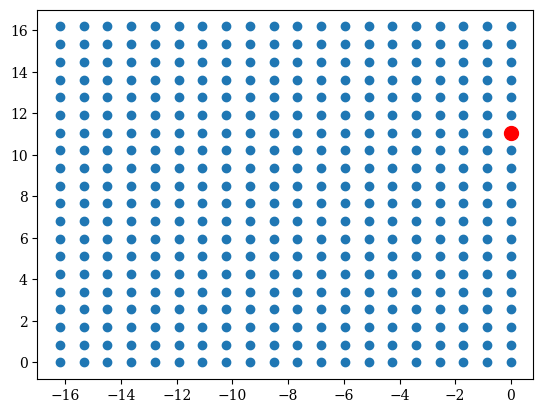

In [ ]:
plt.scatter(positions_rot[:, 0] * rad_to_arcsec, positions_rot[:, 1] * rad_to_arcsec)
plt.scatter(positions_rot[13, 0]*rad_to_arcsec, positions_rot[13, 1]*rad_to_arcsec, c='red', s=100, label='Closest Approach')

In [ ]:
phi_0/np.pi#+2*np.pi

-0.6616347913316158

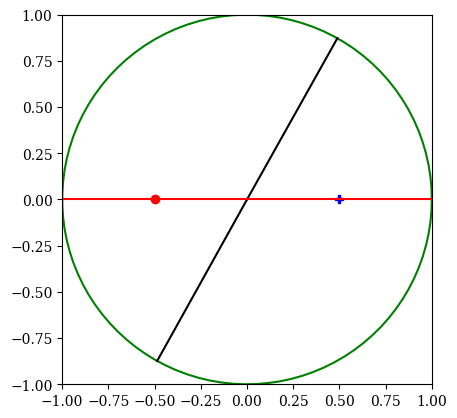

In [ ]:

r = 1
def deg2rad(deg):
    return deg * pi / 180
angles = np.linspace(0 * np.pi, 2 * np.pi, 100) 
xs = np.cos(angles)
ys = np.sin(angles)
plt.plot(xs, ys, color = 'green')

plt.plot(r-0.5, 0, marker = 'P', color = 'blue')
plt.plot(-r+0.5, 0, marker = 'o', color = 'red')
plt.plot([0, r * np.cos(phi_0)], [0, r * np.sin(phi_0)], color = "black")
plt.plot([0, r * np.cos(1.06)], [0, r * np.sin(1.06)], color = "black")

plt.plot([r, -r], [0, 0], color = 'red')
plt.xlim(-r, r)
plt.ylim(-r, r)
plt.gca().set_aspect('equal')

In [ ]:
np.arctan((((position_04[13,0] -4000)*theta_step* rad_to_arcsec)/((position_04[13,1] -4000)*theta_step* rad_to_arcsec)))

np.float64(1.0630056537797883)

In [ ]:
np.arctan(((position_04[13,1] -4000)*theta_step* rad_to_arcsec)/((position_04[13,0] -4000)*theta_step* rad_to_arcsec))

np.float64(0.5077906730151083)

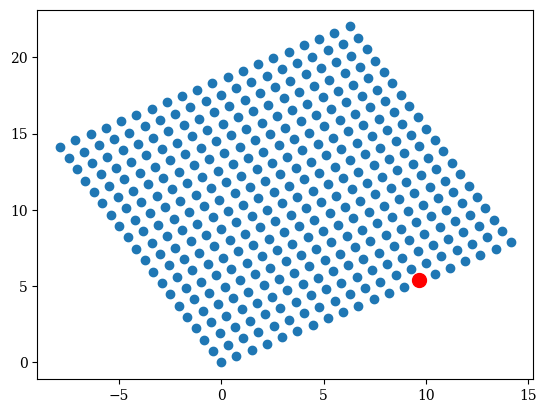

In [ ]:

plt.scatter((position_04[:,0] -4000)*theta_step* rad_to_arcsec, (position_04[:,1] -4000)*theta_step* rad_to_arcsec)
plt.scatter((position_04[13,0] -4000)*theta_step* rad_to_arcsec,
             (position_04[13,1] -4000)*theta_step* rad_to_arcsec, c='red', s=100, label='Closest Approach')

In [ ]:
0 0.03537143016689349
1 0.043472910153662885
2 0.05100339527065601
3 0.06463328997425065
4 0.07936342923504432
5 0.09428613054688025
12 0.0912142340076422
13 0.07118291263982032
14 0.06029496343841955
15 0.06254453174768425
16 0.07265872103507225
17 0.09003379199593148
20 0.06077278645195039
21 0.06568032704453768
22 0.07491597009484446
23 0.07923649258632041
24 0.09099422372084734

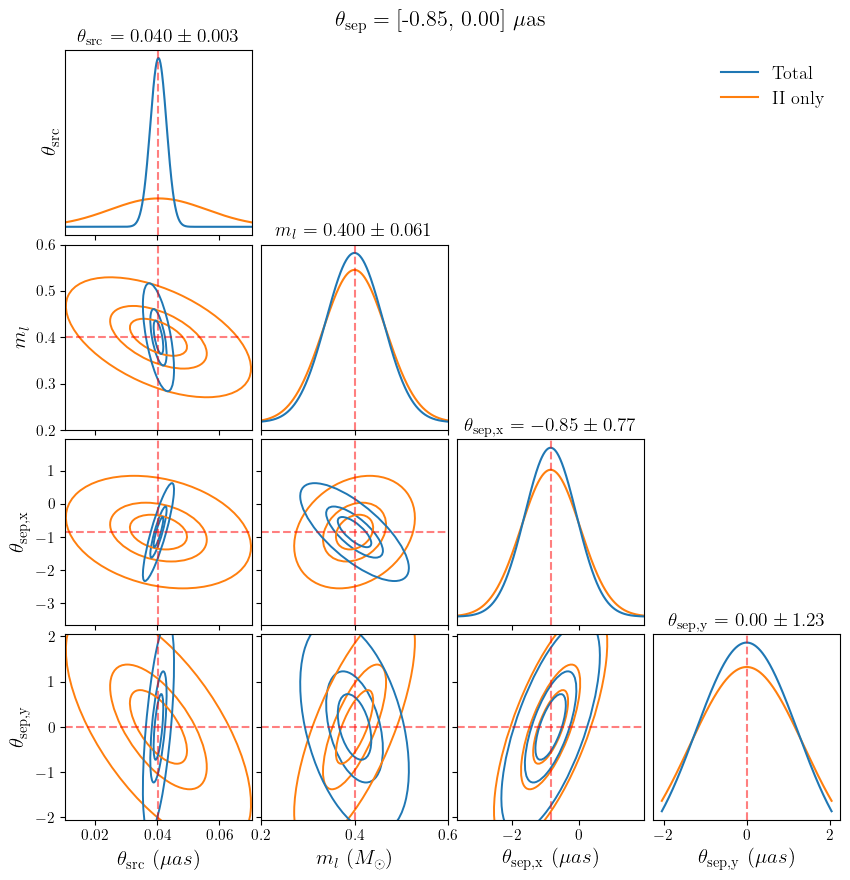

In [90]:
idx=20
pos_x_corner=(positions_rot[idx][0])
pos_y_corner=(positions_rot[idx][1])
mass_04_combo[idx]

titles = [r"$\theta_\text{src}\ (mas)$", r"$m_l\ (M_\odot)$",
          r"$\theta_{\rm sep,x}\ (mas)$", r"$\theta_{\rm sep,y}\ (mas)$"]

varlabels = [r"$\theta_\text{src}$", r"$m_l$", r"$\theta_{\rm sep,x}$", r"$\theta_{\rm sep,y}$"]
units = [r"$\mu as$", r"$M_\odot$", r"$\mu as$", r"$\mu as$"]
precision = [3, 3, 2, 2]

mean_vec = np.array([rad_mas, 0.4, pos_x_corner * rad_to_arcsec, pos_y_corner * rad_to_arcsec])
scales=[.03, .2, 2.8, 2.05] 
limits = np.array([[mean_vec[0]-scales[0], mean_vec[0]+scales[0]], [mean_vec[1]-scales[1], mean_vec[1]+scales[1]],
                   [mean_vec[2]-scales[2], mean_vec[2]+scales[2]], [mean_vec[3]-scales[3], mean_vec[3]+scales[3]]])

cov1 = cov_combo_04[idx] 
cov2 = cov_04[idx]

ndim = len(varlabels)

fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(ndim, ndim, hspace=0.05, wspace=0.05)

axes = np.empty((ndim, ndim), dtype=object)
percentiles = [0.16, 0.84]
colors = ["C0", "C0", "C0"]  # or different colors/styles
linewidths = [0.8, 0.8]

colors2 = ["C1", "C1", "C1"]

for i in range(ndim):
    for j in range(ndim):

        if i < j:
            axes[i, j] = fig.add_subplot(gs[i, j])
            axes[i, j].axis("off")
            continue

        if i == j:
            axes[i, j] = fig.add_subplot(gs[i, j])
        else:
            axes[i, j] = fig.add_subplot( gs[i, j], sharex=axes[j, j],  sharey=axes[i, i] )

for i in range(ndim):
    for j in range(ndim):
        ax = axes[i,j]
        if i < j:
            continue

        if i == j:
            # 1D marginal
            sigma1 = np.sqrt(cov1[i,i])
            sigma2 = np.sqrt(cov2[i,i])
            x = np.linspace(limits[j][0], limits[j][1], 500)#mean_vec[i]-4*sigma1, mean_vec[i]+4*sigma1, 500)
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma2), color="C1")
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma1), color="C0")
            ax.set_yticks([])
            ax.tick_params(left=False)
            nd = precision[i]
            ax.set_title(fr"{varlabels[i]} $= {mean_vec[i]:.{nd}f} \pm {sigma1:.{nd}f}$ ",
                         fontsize=14)
            ax.axvline(mean_vec[[j,i]][1], color='r', linestyle='dashed', alpha=.5)
        else:
            # 2D ellipse
            mean_ij = mean_vec[[j,i]]
            cov1_ij = cov1[np.ix_([j,i],[j,i])]
            cov2_ij = cov2[np.ix_([j,i],[j,i])]
            ax.set_xlim(limits[j][0], limits[j][1])#mean_vec[j]-4*np.sqrt(cov1[j,j]),
                       # mean_vec[j]+4*np.sqrt(cov1[j,j]))
            ax.set_ylim(limits[i][0], limits[i][1])
                        #mean_vec[i]+4*np.sqrt(cov1[i,i]))
            ax.axvline(mean_ij[0], color='r', linestyle='dashed', alpha=.5)
            ax.axhline(mean_ij[1], color='r', linestyle='dashed', alpha=.5)
            plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=1, edgecolor="C1", linewidth=1.4)
            plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=1, edgecolor="C0", linewidth=1.4)

            for p, c, lw in zip(percentiles, colors2, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)
            for p, c, lw in zip(percentiles, colors, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)

        ax.tick_params(labelsize=11)
            
for i in range(ndim):
    for j in range(ndim):
        ax = axes[i, j]
        if i != ndim - 1:
            ax.tick_params(labelbottom=False)
        if j != 0:
            ax.tick_params(labelleft=False)
        #if i!=j+1:
        ax.set_xlabel(f"{varlabels[j]} ({units[j]})", fontsize=15)
        if i>-1 and j==0:
            ax.set_ylabel(f"{varlabels[i]}", fontsize=15)
        
axes[0, -1].plot([], [], color="C0", label="Total")
axes[0, -1].plot([], [], color="C1", label="II only")
axes[0, -1].legend(frameon=False, fontsize=13)

title=r'$\theta_{\mathrm{sep}} = [$' + str(format(pos_x_corner*rad_to_arcsec, '.2f')) + ', ' + str(format(pos_y_corner*rad_to_arcsec, '.2f')) + r'$]\ \mu$as'
fig.text( 0.5, 0.92, title, ha='center', va='top', fontsize=16)
#plt.text(-25, 1.45, r'$\theta_{{sep}} = [-0.31,  0.57]\ \mu$as', fontsize=18);
#plt.show()

plt.savefig('figures/corner04_ell.pdf', bbox_inches='tight')
#FileLink('figures/corner04_ell.pdf')

### Interpolate errors

In [11]:
n = int(np.sqrt(len(x_rot)))

x_grid = np.unique(positions_rot[:, 0].round(decimals=15))#*theta_step * image_size
x_grid = np.concat((x_grid, (-x_grid[len(x_grid)-2::-1])))
y_grid = np.unique(positions_rot[:, 1].round(decimals=15))#*theta_step * image_size
y_grid = np.concat((-y_grid[::-1], (y_grid[1:])))

rad_grid  = rad_04_combo.reshape(n, n)
mass_grid = mass_04_combo.reshape(n, n)
xpos_grid = posx_04_combo.reshape(n, n)
ypos_grid = posy_04_combo.reshape(n, n)


In [12]:
rad_grid  = one_quad_to_full(rad_04_combo, n)
mass_grid = one_quad_to_full(mass_04_combo, n)
xpos_grid = one_quad_to_full(posx_04_combo, n)
ypos_grid = one_quad_to_full(posy_04_combo, n)


In [13]:
# Build interpolators
rad_spline  = RegularGridInterpolator([x_grid, y_grid], rad_grid, method='linear')
mass_spline = RegularGridInterpolator([x_grid, y_grid], mass_grid, method='linear')
xpos_spline = RegularGridInterpolator([x_grid, y_grid], xpos_grid, method='linear') #takes position in radians, returns in mas
ypos_spline = RegularGridInterpolator([x_grid, y_grid], ypos_grid, method='linear')

In [14]:
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
#mass_interp = mass_spline.ev(X_fine.ravel(), Y_fine.ravel()).reshape(Y_fine.shape)

In [15]:
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)
rad_interp = rad_spline(points).reshape(X_fine.shape)
mass_interp = mass_spline(points).reshape(X_fine.shape)
xpos_interp = xpos_spline(points).reshape(X_fine.shape)
ypos_interp = ypos_spline(points).reshape(X_fine.shape)

### Interpolate fisher matricies for m=0.8

In [16]:
f_combo_04=[]
for i in range(len(cov_combo_04)):
    f_combo_04.append(np.linalg.inv(cov_combo_04[i]))
f_combo_04=np.array(f_combo_04)
f_combo_04 = f_combo_04.reshape(n, n, 4, 4)
f_combo_04  = matrix_to_full(f_combo_04, n)

In [17]:
splines_f04 = [[RectBivariateSpline(x_grid, y_grid, f_combo_04[:, :, i, j])#, s=1e-24)
            for j in range(4)] for i in range(4)]
def fisher_spline(pos_arr):
    x=pos_arr[0]
    y=pos_arr[1]
    return np.array([[splines_f04[i][j](x, y)[0,0] for j in range(4)] for i in range(4)])

In [18]:
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 400)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 400)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')


In [19]:
Z_det=np.empty((len(fine_grid_x), len(fine_grid_y)))
for i, x in enumerate(fine_grid_x):
    for j, y in enumerate(fine_grid_y):
       
        f_original = fisher_spline([x, y])      
        Z_det[i, j] = np.linalg.det(f_original) 

In [20]:
interpolators = [[None for j in range(4)] for i in range(4)]

for i in range(4):
    for j in range(4):
        # Linear interpolation; 'bounds_error=False' allows extrapolation if needed
        interpolators[i][j] = RegularGridInterpolator(
            (x_grid, y_grid),
            f_combo_04[:, :, i, j], bounds_error=False, method='linear', fill_value=np.nan)
def fisher_interp_linear(pos):
    x, y = pos
    M = np.zeros((4, 4))
    for i in range(4):
        for j in range(4):
            M[i, j] = np.asarray(interpolators[i][j]([x, y])).ravel()[0]
    # enforce symmetry
    M = 0.5 * (M + M.T)
    return M
def fisher_interp_grid(pos):
    x, y = pos[:, 0], pos[:, 1]
    N = len(x)

    M = np.zeros((N, 4, 4))
    for i in range(4):
        for j in range(4):
            M[:, i, j] = interpolators[i][j](np.column_stack((x, y)))

    # enforce symmetry on the last two axes only
    M = 0.5 * (M + np.swapaxes(M, -1, -2))
    return M

In [21]:
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)
Fvals_interp = fisher_interp_grid(points).reshape((200,200,4,4))


### Interpolate chi^2, centroids

In [22]:
chi_grid  = one_quad_to_full(chi_combo_04, n)

fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)

chi_spline  = RegularGridInterpolator([x_grid, y_grid], chi_grid, bounds_error=False, method='linear', fill_value=np.nan)
chi_interp  = chi_spline(points).reshape(X_fine.shape)

In [23]:

centroids=centroids.reshape(n,n,2,4)
Jcent_grid  = Jac_to_full(centroids, n)

interpolators_cent=[[None for i in range(4)] for a in range(2)]

for a in range(2):        # centroid x/y
    for i in range(4):    # parameters
        interpolators_cent[a][i] = RegularGridInterpolator(
        (x_grid, y_grid),
        Jcent_grid[:, :, a, i], bounds_error=False, method='linear', fill_value=np.nan)

def Jcent_interp(pos):
    x, y = pos
    J = np.zeros((2, 4))
    for a in range(2):
        for i in range(4):
            J[a, i] = np.asarray(interpolators_cent[a][i]([x, y])).ravel()[0]
    return J

cent_pres  = one_quad_to_full(cent_pres, n)
cent_spline = RegularGridInterpolator([x_grid, y_grid], cent_pres, method='linear', fill_value=np.nan)
cent_interp = cent_spline(points).reshape(X_fine.shape)

sigma_c1  = one_quad_to_full(sigma_c1, n)
sigma_c1_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c1, method='linear', fill_value=np.nan)
sigma_c1_interp = sigma_c1_spline(points).reshape(X_fine.shape)

sigma_c2  = one_quad_to_full(sigma_c2, n)
sigma_c2_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c2, method='linear', fill_value=np.nan)
sigma_c2_interp = sigma_c2_spline(points).reshape(X_fine.shape)


sigma_c1_res  = one_quad_to_full(sigma_c1_res, n)
sigma_c1res_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c1_res, method='linear', fill_value=np.nan)
sigma_c1res_interp = sigma_c1res_spline(points).reshape(X_fine.shape)

sigma_c2_res  = one_quad_to_full(sigma_c2_res, n)
sigma_c2res_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c2_res, method='linear', fill_value=np.nan)
sigma_c2res_interp = sigma_c2res_spline(points).reshape(X_fine.shape)


In [24]:
chi_grid_II  = one_quad_to_full(chis_04_II, n)
chi_spline_II  = RegularGridInterpolator([x_grid, y_grid], chi_grid_II, bounds_error=False, method='linear', fill_value=np.nan)

chi_grid_mag  = one_quad_to_full(chis_04_mag, n)
chi_spline_mag  = RegularGridInterpolator([x_grid, y_grid], chi_grid_mag, bounds_error=False, method='linear', fill_value=np.nan)

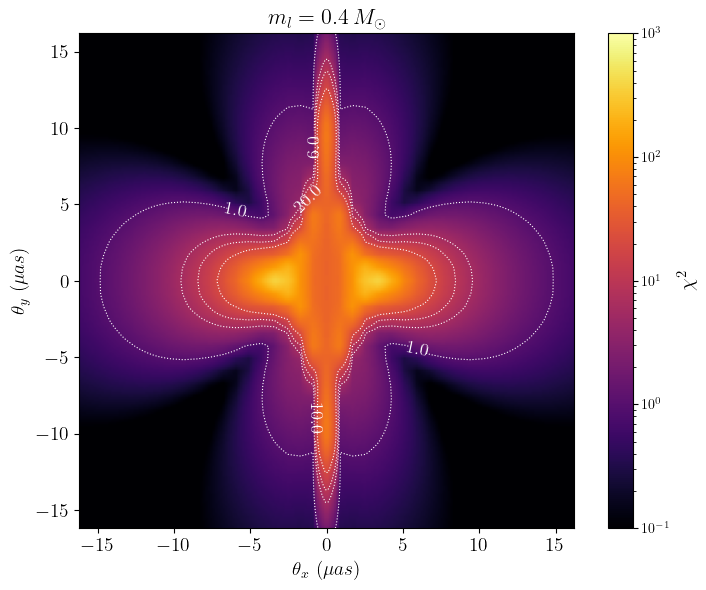

In [28]:
Z = np.flipud(chi_interp).T
X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

levels=[1, 6, 10, 20]
fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(Z, origin='lower', extent=extent, cmap='inferno', norm=matplotlib.colors.LogNorm(vmin=.1,vmax=1000),)
contours = ax.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax.clabel(contours, inline=True, fontsize=13, fmt="%.1f")

cbar = plt.colorbar(im, ax=ax, fraction=0.045, pad=.03)
cbar.set_label(r'$\chi^2$', fontsize=15)

ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=12)
plt.title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()

plt.savefig('figures/chi04.pdf', bbox_inches='tight')


In [29]:
# Grid spacing (assumes a regular grid)
dx = X[0, 1] - X[0, 0]
dy = Y[1, 0] - Y[0, 0]

# Mask of detectable region
mask = Z > 6

# Total area where Z < 6
area = np.sum(mask) * dx * dy

# Equivalent circular radius
r_equiv = np.sqrt(area / np.pi)

print(f"Area-equivalent detectable radius = {r_equiv/rad_to_arcsec/theta_E_4} theta_E")

Area-equivalent detectable radius = [4.36037965] theta_E


In [39]:
area

np.float64(157.47282388197814)

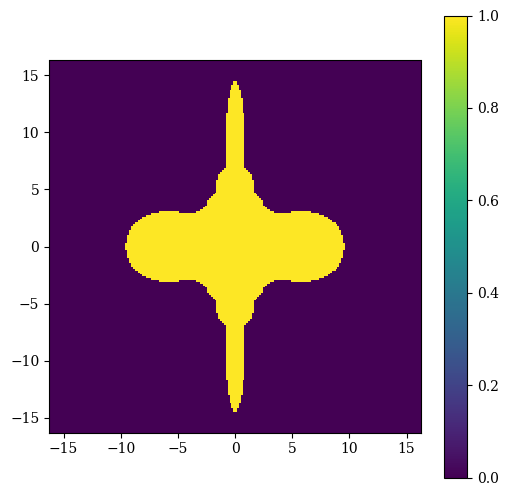

In [40]:
plt.figure(figsize=(6,6))
plt.pcolormesh(X, Y, mask, shading='nearest')
plt.gca().set_aspect('equal')
plt.colorbar()

In [36]:
print("Fraction of pixels:", mask.mean())

area = mask.sum() * dx * dy
print("Area =", area)
print("Equivalent radius =", np.sqrt(area/np.pi))

Fraction of pixels: 0.8513
Area = 901.523974248339
Equivalent radius = 16.940011618500957


### Error Plots

In [91]:
orig_map=plt.cm.get_cmap('cividis')

# reversing the original colormap using reversed() function
reversed_map = orig_map.reversed()

bulk_vel=400
bulk_vel_err=100
vel_disp=178
vel_disp_err=35

# Apparent (image-fixed-frame) proper-motion scales for the map annotations
# (see get_velocities): the extremes lie along/perpendicular to the shear axis and
# are given by the eigenvalues of B = A^{-1} times the unlensed rate.
nu_unlensed = np.sqrt(bulk_vel**2+vel_disp**2)*1e5/((1+z_l)*D_l)*365.25*24*3600*rad_to_arcsec  # uas/yr
eigB = np.abs(np.linalg.eigvalsh(B_matrix))
mu_x = nu_unlensed*eigB.min()   # perpendicular to the shear axis (horizontal in plots)
mu_y = nu_unlensed*eigB.max()   # along the shear axis (vertical in plots)

/tmp/ipykernel_3494866/2471395885.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  orig_map=plt.cm.get_cmap('cividis')


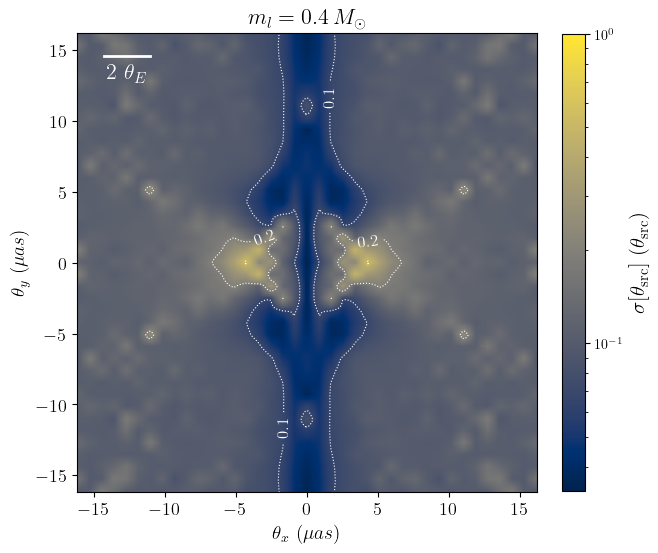

In [94]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6.6, 5.9))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(rad_interp).T/rad_mas

levels=[1/15, 1/5, .5]
im=ax1.imshow(Z, origin='lower', cmap=orig_map, extent=extent,
              norm=matplotlib.colors.LogNorm(vmin=1/30, vmax=1))
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
cbar.set_label(r'$\sigma [\theta_\text{src}] \ (\theta_\text{src})$', fontsize=15)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=12, fmt="%.1f")

#scale bar: 2 theta_E, same placement convention in all maps and masses
scale_length = float(np.ravel(2*theta_E_4*rad_to_arcsec)[0])  # scalar: text positions must not be arrays
x_start = np.min(fine_grid_x) - 4.4 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text((x_start + x_end) / 2, y_pos * .865, r"$ 2 \ \theta_{E}$", color='white', ha='center', va='bottom', fontsize=16,
         fontweight='black')
ax1.tick_params(axis='both', which='major', labelsize=13)
ax1.tick_params(axis='both', which='minor', labelsize=12)
plt.title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()

plt.savefig('figures/rad_04.pdf', bbox_inches='tight')


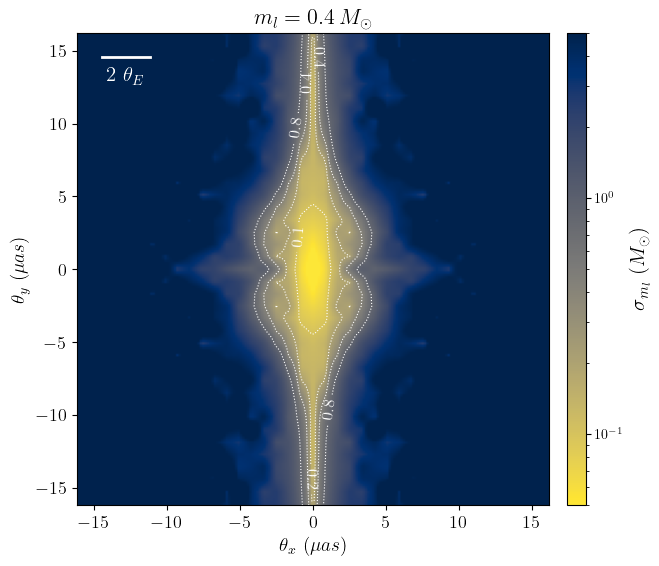

In [99]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(mass_interp).T

levels=[.1, .2, .4, .8]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, norm=matplotlib.colors.LogNorm(vmin=5e-2, vmax=5), extent=extent)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma_{m_l} \ (M_\odot)$', fontsize=15)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=12, fmt="%.1f")

#scale bar: 2 theta_E, same placement convention in all maps and masses
scale_length = float(np.ravel(2*theta_E_4*rad_to_arcsec)[0])  # scalar: text positions must not be arrays
x_start = np.min(fine_grid_x) - 4.45 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text((x_start + x_end) / 2, y_pos * .865, r"$ 2 \ \theta_{E}$", color='white', ha='center', va='bottom', fontsize=15,
         fontweight='black')
ax1.tick_params(axis='both', which='major', labelsize=13)
ax1.tick_params(axis='both', which='minor', labelsize=12)
ax1.set_title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/mass_04.pdf')


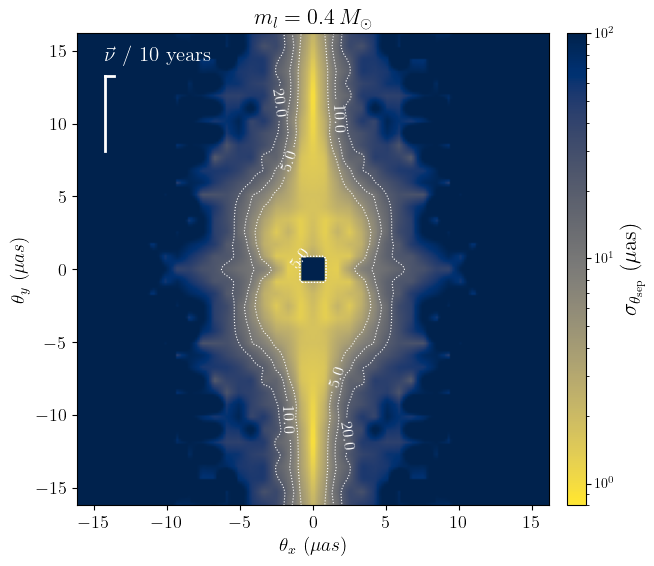

In [100]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.sqrt(np.flipud(xpos_interp).T**2+np.flipud(ypos_interp).T**2)

levels=[5, 10, 20]
im=ax1.imshow(Z, origin='lower',cmap=reversed_map,norm=matplotlib.colors.LogNorm(vmin=8e-1, vmax=1e2), extent=extent)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma_{\theta_{\rm sep}} \ (\mu \rm as)$', fontsize=16)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=12, fmt="%.1f")

# proper-motion annotation (apparent nu x 10 yr along / perpendicular to the shear
# axis), anchored top-left at a fixed fraction of the map extent so its placement is
# identical across the four lens masses (the arrow lengths are physical, i.e.
# mass-independent).
scale_length_x=mu_x*10
scale_length_y=mu_y*10
x_start = 0.88*extent[0]
x_end = x_start + scale_length_x
y_pos = 0.82*extent[3]
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.plot([x_start, x_start], [y_pos-scale_length_y, y_pos], color='white', lw=2)
ax1.text(x_start, y_pos * 1.05, r"$\vec{\nu} \ / $ 10 years", color='white', ha='left', va='bottom', fontsize=15,
         fontweight='black')

ax1.tick_params(axis='both', which='major', labelsize=13)
ax1.tick_params(axis='both', which='minor', labelsize=12)
ax1.set_title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/pos_04.pdf')


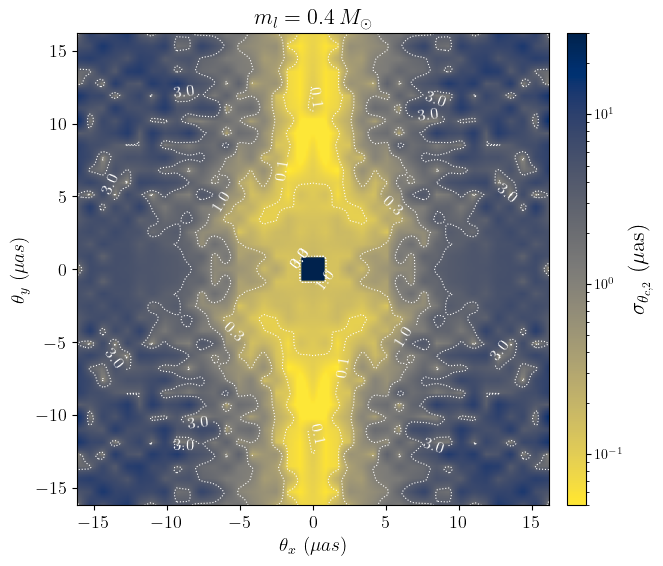

In [109]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c2_interp).T

levels=[.1, .3, 1, 3]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=5e-2, vmax=3e1))
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma_{\theta_{c,2}} \ (\mu \rm as)$', fontsize=16)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=12, fmt="%.1f")

ax1.tick_params(axis='both', which='major', labelsize=13)
ax1.tick_params(axis='both', which='minor', labelsize=12)
ax1.set_title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/thetac2_04.pdf')


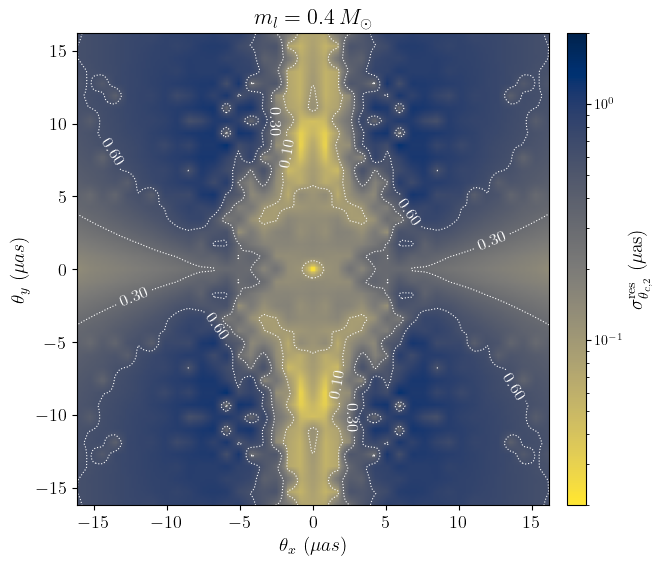

In [103]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c2res_interp).T

levels=[.1, .3, .6]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=2e-2, vmax=2e0))
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma^{\rm res}_{\theta_{c,2}} \ (\mu \rm as)$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=12, fmt="%.2f")


ax1.tick_params(axis='both', which='major', labelsize=13)
ax1.tick_params(axis='both', which='minor', labelsize=12)
ax1.set_title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/thetac2res_04.pdf')


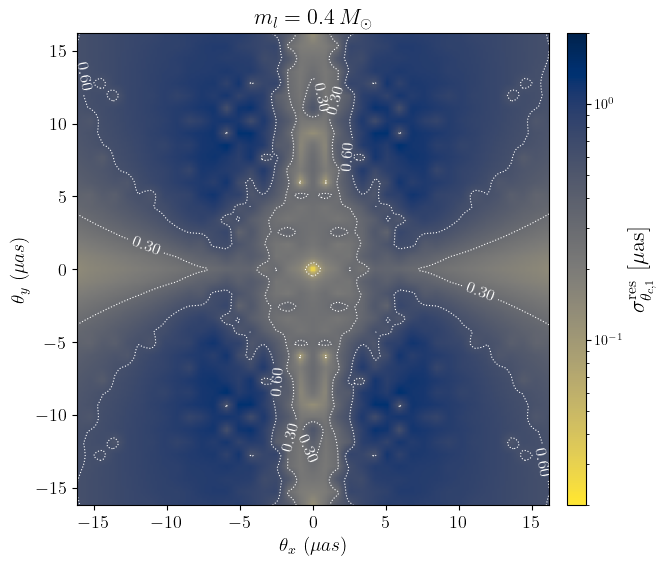

In [107]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c1res_interp).T

levels=[.1, .3, .6]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=2e-2, vmax=2e0))
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma^{\rm res}_{\theta_{c,1}} \ [\mu \rm as]$', fontsize=16)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=12, fmt="%.2f")

ax1.tick_params(axis='both', which='major', labelsize=13)
ax1.tick_params(axis='both', which='minor', labelsize=12)
ax1.set_title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/thetac1res_04.pdf')


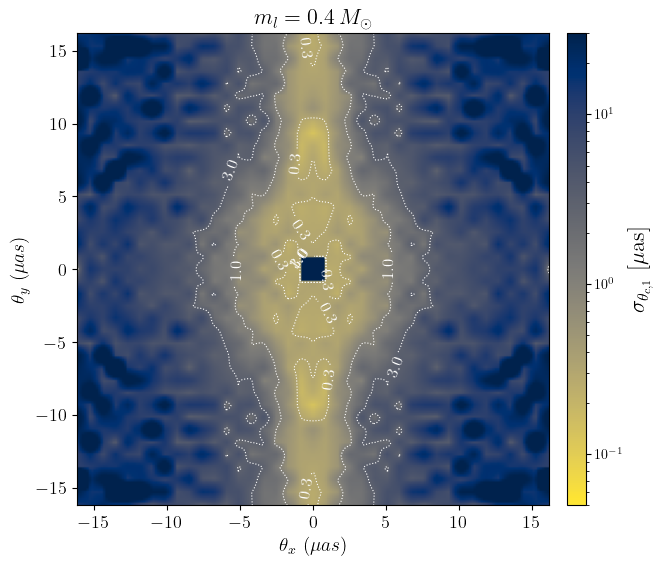

In [108]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c1_interp).T

levels=[.1, .3, 1, 3]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=5e-2, vmax=3e1))
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma_{\theta_{c,1}} \ [\mu \rm as]$', fontsize=16)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=12, fmt="%.1f")


ax1.tick_params(axis='both', which='major', labelsize=13)
ax1.tick_params(axis='both', which='minor', labelsize=12)
ax1.set_title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.savefig('figures/thetac1_04.pdf')


### Uncertainties as a function of min impact parameter

In [25]:
# slighly modified from before to record full centroid matricies
def average_errors_traj(bulk_vel,bulk_vel_err,vel_disp,vel_disp_err,theta_max,N,redshift,lens_dist,B_matrix,dist,chi_spline,dt_days=182.0,max_time_days=5*365.0,n_its=100,fisher_spline=fisher_interp_linear):

    fisher_thetas=[]
    cov_thetas=[]
    uncert_thetas=[]
    vels=[]
    chi_all=[]
    retries=[]
    Jcents=[]
    acc_covs=[]
    acc_sigmas=[]
    cent_cov_trajs=[]
    pos_trajs=[]
    time_trajs=[]

    for it in range(n_its):

        test_traj=sim_rand_traj(bulk_vel,bulk_vel_err,vel_disp,vel_disp_err,theta_max,N,redshift,lens_dist,B_matrix,dist,dt_days=dt_days,max_time_days=max_time_days)

        positions_traj=test_traj['positions_rad']
        times_traj=test_traj['times_days']

        retry=0

        fisher_alpha=np.array([fisher_spline(p) for p in positions_traj])
        chi_traj=np.array([chi_spline(p) for p in positions_traj])
        centJ_traj=np.array([Jcent_interp(p) for p in positions_traj]).reshape(-1,2,4)

        fisher_theta_traj=f_alpha_to_f_Theta(fisher_alpha,times_traj*(3600*24))
        cov_Theta,uncert_Theta=parameter_uncertainties(fisher_theta_traj,theta_step,printout=False,numstars=1)

        while np.any(np.isnan(uncert_Theta)):

            retry+=1

            test_traj=sim_rand_traj(bulk_vel,bulk_vel_err,vel_disp,vel_disp_err,theta_max,N,redshift,lens_dist,B_matrix,dist,dt_days=dt_days,max_time_days=max_time_days)

            positions_traj=test_traj['positions_rad']
            times_traj=test_traj['times_days']

            fisher_alpha=np.array([fisher_spline(p) for p in positions_traj])
            chi_traj=np.array([chi_spline(p) for p in positions_traj])
            centJ_traj=np.array([Jcent_interp(p) for p in positions_traj]).reshape(-1,2,4)

            fisher_theta_traj=f_alpha_to_f_Theta(fisher_alpha,times_traj*(3600*24))
            cov_Theta,uncert_Theta=parameter_uncertainties(fisher_theta_traj,theta_step,printout=False,numstars=1)

        retries.append(retry)

        pos_trajs.append(positions_traj)
        time_trajs.append(times_traj)
        vels.append(test_traj['velocity_kms'])

        chi_all.append(np.sum(chi_traj))

        C_alpha=np.linalg.inv(fisher_alpha)
        centroid_cov_traj=np.einsum('nij,njk,nlk->nil',centJ_traj,C_alpha,centJ_traj)

        cent_cov_trajs.append(centroid_cov_traj)

        acc_cov,sigma_acc=centroid_acceleration_uncertainty(centroid_cov_traj,times_traj)
        acc_covs.append(acc_cov)
        acc_sigmas.append(sigma_acc)

        Cinv_tot=np.sum(np.linalg.inv(centroid_cov_traj),axis=0)
        C_cent_tot=np.linalg.inv(Cinv_tot)
        Jcents.append(C_cent_tot)

        fisher_thetas.append(f_alpha_to_f_Theta(fisher_alpha,times_traj*(3600*24)))

        cov_v_cm,cov_v_kms,sigma_v_kms=unlens_sigma_from_cov(cov_Theta,B_matrix,redshift,lens_dist)

        cov_Theta,uncert_Theta=parameter_uncertainties(fisher_thetas[-1],theta_step,printout=False,numstars=1)

        uncert_unlensed=np.array(uncert_Theta.copy())
        uncert_unlensed[4]=sigma_v_kms[0]*4.848136811e-12
        uncert_unlensed[5]=sigma_v_kms[1]*4.848136811e-12

        uncert_thetas.append(uncert_unlensed)

    cov_thetas=np.array(cov_thetas)
    Jcents=np.array(Jcents)
    chi_all=np.array(chi_all)

    cov_avg=np.mean(cov_thetas,axis=0)

    uncert_thetas=np.array(uncert_thetas)
    uncert_avg=np.sum(uncert_thetas,axis=0)/n_its

    vels=np.array(vels)

    return cov_thetas,cov_avg,uncert_thetas,uncert_avg,vels,chi_all,retries,Jcents,acc_sigmas,cent_cov_trajs,pos_trajs,time_trajs,acc_covs


In [26]:
from II_funcs import *

In [32]:
theta_E_8=np.sqrt(4*G*0.8*2e33/c**2*D_ls/(D_s*D_l))
theta_E_4=np.sqrt(4*G*0.4*2e33/c**2*D_ls/(D_s*D_l))
impact_params=np.linspace(0.3*theta_E_8,5.9*theta_E_8,40)

chi_tots,uncert_avgs,n_retries=[],[],[]
chi_dists,uncert_dists=[],[]
cent_all,acc_sigmas=[],[]
traj_cov_cent=[]
pos_traj,time_traj=[],[]
acc_covs_all = []   # new list

for impact_param in impact_params:
    
    out=average_errors_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, np.max(x_grid), 8000, 
                            z_l, D_l, B_matrix, impact_param, chi_spline, fisher_spline=fisher_interp_linear, 
                            n_its=10000, dt_days=91.25, max_time_days=4*365.0)

    chi_tots.append(np.mean(out[5]))
    uncert_avgs.append(np.mean(out[2],axis=0))
    n_retries.append(out[6])

    chi_dists.append(out[5])
    uncert_dists.append(out[2])

    cent_all.append(out[9])
    acc_sigmas.append(out[8])
    traj_cov_cent.append(out[9])

    pos_traj.append(out[10])
    time_traj.append(out[11])
    acc_covs_all.append(out[12])

results = {
    "impact_params": impact_params,
    "chi_tots": np.array(chi_tots),
    "cent_all": np.array(cent_all),
    "uncert_avgs": np.array(uncert_avgs),
    "n_retried": np.array(n_retries),
    "chi_dists": np.array(chi_dists, dtype=object),
    "uncert_dists": np.array(uncert_dists, dtype=object),
    "acc_sigmas": np.array(acc_sigmas, dtype=object),
    "cent_traj": np.array(traj_cov_cent, dtype=object),
    "pos_traj": np.array(pos_traj, dtype=object),
    "time_traj": np.array(time_traj, dtype=object),
    "acc_covs": np.array(acc_covs_all, dtype=object),
    }

filename = "avgs_04_8yr_acc.npz"
try:
    existing = np.load(filename, allow_pickle=True)

    combined = {}

    old_nimpact = len(existing["impact_params"])
    new_nimpact = len(impact_params)

    for key, new_vals in results.items():
        old_vals = existing[key]

        if key == "impact_params":
            combined[key] = np.hstack([old_vals, new_vals])

        elif key == "uncert_avgs":
            combined[key] = np.vstack([old_vals, new_vals])

        elif key in ["chi_tots"]:
            combined[key] = np.hstack([old_vals, new_vals])

        elif key in ["cent_all", "acc_sigmas", "cent_traj", "pos_traj", "time_traj", "chi_dists", "uncert_dists", 'acc_covs']:
            combined[key] = np.hstack([old_vals, new_vals])

        elif key == "n_retried":
            combined[key] = np.hstack([old_vals, new_vals])

        else:
            combined[key] = np.hstack([old_vals, new_vals])

except FileNotFoundError:
    combined = results

np.savez(filename, **combined)

/mnt/home/amoran/miniforge3/envs/GW_all/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/mnt/home/amoran/miniforge3/envs/GW_all/lib/python3.10/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [27]:
# load it back in
data = np.load("avgs_04_8yr_acc.npz", allow_pickle=True)

impact_params_all = data["impact_params"]
chi_all= data["chi_tots"]
uncert_all = data["uncert_avgs"]
chi_dists_all = data["chi_dists"]
uncert_dists_all = data["uncert_dists"] 

uniq = np.unique(impact_params_all)
chi_mean   = np.zeros(len(uniq))
uncert_mean = np.zeros((len(uniq), uncert_all.shape[1]))

for i, u in enumerate(uniq):
    mask = impact_params_all == u
    chi_mean[i]   = chi_all[mask].mean()
    uncert_mean[i] = uncert_all[mask].mean(axis=0)

impact_params = uniq
chi_full=np.array(chi_dists_all)
uncert_full=np.array(uncert_dists_all)
chi_dists_all.shape

(40, 12000)

In [28]:
impact_params/theta_E_4

array([0.42426407, 0.62733063, 0.83039719, 1.03346376, 1.23653032,
       1.43959688, 1.64266345, 1.84573001, 2.04879657, 2.25186313,
       2.4549297 , 2.65799626, 2.86106282, 3.06412939, 3.26719595,
       3.47026251, 3.67332907, 3.87639564, 4.0794622 , 4.28252876,
       4.48559532, 4.68866189, 4.89172845, 5.09479501, 5.29786158,
       5.50092814, 5.7039947 , 5.90706126, 6.11012783, 6.31319439,
       6.51626095, 6.71932752, 6.92239408, 7.12546064, 7.3285272 ,
       7.53159377, 7.73466033, 7.93772689, 8.14079346, 8.34386002])

In [29]:
#check that all of these are in the area under chi^2=10, and they are!
n_retrys=data['n_retried']
cut=0
for i in range(len(n_retrys)):
    tries=np.sum(n_retrys[i])
    #print(np.percentile(chi_full, 50, axis=1)[i])
    if tries>0:
        print("pos", np.array(impact_params/theta_E_4)[i], ':', tries)
    if np.percentile(chi_full, 50, axis=1)[i]<10 and cut==0:
        print('cutoff is ', np.array(impact_params/theta_E_4)[i])
        print('limit x axis to ', np.array(impact_params/theta_E_4)[i-1])
        xlim=np.array(impact_params/theta_E_4)[i-1]
        cut=10
        

if 'xlim' not in globals():
    xlim = float(np.max(impact_params/theta_E_4))
    print('median chi^2 >= 10 throughout; xlim set to full range =', xlim)


cutoff is  8.14079345519897
limit x axis to  7.9377268923966815


In [32]:
def apply_residual_cov_fast(cent_cov_traj, dtheta):
    I2 = np.eye(2)
    Cinv = np.linalg.inv(cent_cov_traj)
    prior = I2[None,None,None,:,:] / (dtheta[:,:,:,None,None]**2 + 1e-30)
    return np.linalg.inv(Cinv + prior)


def acceleration_sigma_from_cov_traj_fast(cent_cov_traj, times):
    n_imp, n_traj, n_t = times.shape
    t = times * 86400.0
    G = np.zeros((n_imp, n_traj, n_t, 2, 6))

    G[:,:,:,0,0] = 1
    G[:,:,:,0,2] = t
    G[:,:,:,0,4] = 0.5*t**2

    G[:,:,:,1,1] = 1
    G[:,:,:,1,3] = t
    G[:,:,:,1,5] = 0.5*t**2
    Cinv = np.linalg.inv(cent_cov_traj)
    GT = np.swapaxes(G, -1, -2)
    F = np.einsum('...ij,...jk,...kl->...il', GT, Cinv, G)
    F = np.sum(F, axis=2)
    cov = np.linalg.inv(F)
    return np.sqrt(np.diagonal(cov[:,:,4:6,4:6], axis1=-2, axis2=-1))
def acceleration_sigma_from_cov_traj_eig(cent_cov_traj, times):
    """
    Like acceleration_sigma_from_cov_traj_fast, but instead of returning the
    sqrt of the diagonal entries of the 2x2 acceleration covariance block
    (i.e. per-axis sigmas), this diagonalizes that 2x2 block and returns the
    sqrt of its eigenvalues, sorted ascending.

    Returns
    -------
    sigma_min, sigma_max : arrays of shape (n_imp, n_traj)
        sigma_min is sqrt(min eigenvalue) -- the tightest-constrained direction.
        sigma_max is sqrt(max eigenvalue) -- the loosest-constrained direction.
    """
    n_imp, n_traj, n_t = times.shape
    t = times * 86400.0
    G = np.zeros((n_imp, n_traj, n_t, 2, 6))

    G[:,:,:,0,0] = 1
    G[:,:,:,0,2] = t
    G[:,:,:,0,4] = 0.5*t**2

    G[:,:,:,1,1] = 1
    G[:,:,:,1,3] = t
    G[:,:,:,1,5] = 0.5*t**2

    Cinv = np.linalg.inv(cent_cov_traj)
    GT = np.swapaxes(G, -1, -2)
    F = np.einsum('...ij,...jk,...kl->...il', GT, Cinv, G)
    F = np.sum(F, axis=2)
    cov = np.linalg.inv(F)

    # 2x2 acceleration block: indices 4:6 correspond to (ax, ay)
    acc_block = cov[:, :, 4:6, 4:6]  # shape (n_imp, n_traj, 2, 2)

    # eigvalsh is for symmetric/Hermitian matrices and returns eigenvalues
    # in ascending order -- exactly what we want (min first, max second)
    eigvals = np.linalg.eigvalsh(acc_block)  # shape (n_imp, n_traj, 2)

    sigma_min = np.sqrt(eigvals[..., 0])
    sigma_max = np.sqrt(eigvals[..., 1])

    return sigma_min, sigma_max
def acc_sigma_min_max_from_covs(acc_covs):
    """
    acc_covs : array-like, shape (n_its, 2, 2) -- per-sample acceleration
        covariance matrices (rad/s^2)^2.

    Returns
    -------
    sigma_min, sigma_max : arrays, shape (n_its,)
        sqrt of the min/max eigenvalue of each 2x2 covariance matrix.
    """
    acc_covs = np.asarray(acc_covs, dtype=np.float64)
    eigvals = np.linalg.eigvalsh(acc_covs)   # shape (n_its, 2), ascending order
    sigma_min = np.sqrt(eigvals[..., 0])
    sigma_max = np.sqrt(eigvals[..., 1])
    return sigma_min, sigma_max

In [33]:
# |Delta theta_c| interpolant over the shear-frame grid (RADIANS), used to cap the
# per-epoch centroid covariance along trajectories (Eq. 24 of the paper).
dtheta_grid_rad = one_quad_to_full(np.linalg.norm(cent0_grid, axis=-1), n)
dtheta_spline = RegularGridInterpolator([x_grid, y_grid], dtheta_grid_rad,
                                        bounds_error=False, method='linear', fill_value=np.nan)

In [34]:
acc_covs_data = data["acc_covs"]  # object array, one (n_its,2,2) block per impact param

sigma_min_list = []
sigma_max_list = []
for covs_i in acc_covs_data:
    smin, smax = acc_sigma_min_max_from_covs(covs_i)
    sigma_min_list.append(smin)
    sigma_max_list.append(smax)

# percentile + median across n_its for each impact parameter
acc_sigma_min_16 = np.array([np.nanpercentile(s, 16) for s in sigma_min_list])
acc_sigma_min_50 = np.array([np.nanpercentile(s, 50) for s in sigma_min_list])
acc_sigma_min_84 = np.array([np.nanpercentile(s, 84) for s in sigma_min_list])

In [35]:
acc_sigmas=data["acc_sigmas"]
acc_arr = np.array(acc_sigmas.tolist(), dtype=np.float64)
acc_sigma_mag = np.linalg.norm(acc_arr, axis=-1)
acc_sigma_mean = acc_sigma_mag  # name kept for downstream cells
acc_sigma_84 = np.nanpercentile(acc_sigma_mag, 84, axis=-1)
acc_sigma_16 = np.nanpercentile(acc_sigma_mag, 16, axis=-1)
acc_sigma_50 = np.nanpercentile(acc_sigma_mag, 50, axis=-1)

cent_traj = data["cent_traj"]
times = data["time_traj"]
pos_traj = data["pos_traj"] #rad

pos = np.array(pos_traj, dtype=np.float64)
dtheta_traj = dtheta_spline(pos)

cent_cov_res = apply_residual_cov_fast(np.array(cent_traj, dtype=np.float64), dtheta_traj)

acc_sigma_res = acceleration_sigma_from_cov_traj_fast(cent_cov_res, np.asarray(times, dtype=np.float64))
acc_sigma_min_res2, acc_sigma_max_res2 = acceleration_sigma_from_cov_traj_eig(cent_cov_res, np.asarray(times, dtype=np.float64))
acc_sigma_res2 = acc_sigma_min_res2  

In [36]:
mag_acc_sig_r=np.linalg.norm(acc_sigma_res, axis=-1)
acc_sigma_res_50 = np.nanpercentile(mag_acc_sig_r, 50, axis=-1)

acc_sigma_res2_50 = np.nanpercentile(acc_sigma_res2, 50, axis=-1)


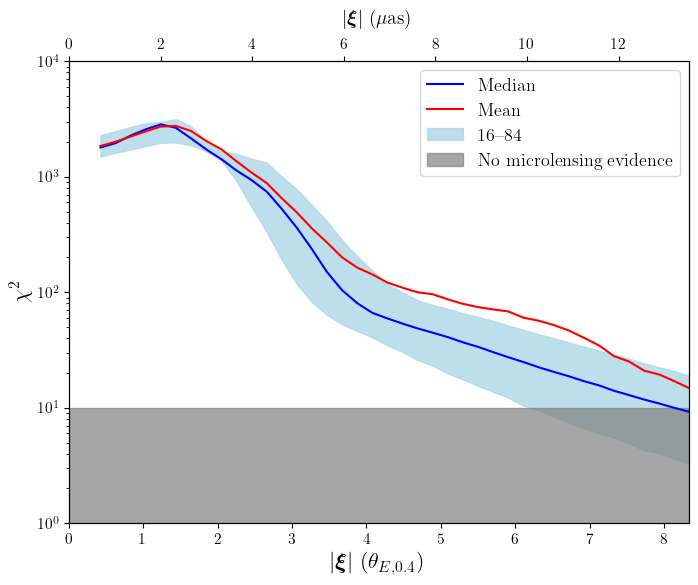

In [38]:
p16= np.array(np.percentile(chi_full, 16, axis=1), dtype=float)
p84 = np.array(np.percentile(chi_full, 84, axis=1), dtype=float)
xlim_real=xlim*1.05
fig,ax = plt.subplots(figsize=(8,6))

ax.plot(impact_params / theta_E_4, np.percentile(chi_full, 50, axis=1), color='blue', label='Median')
ax.plot(impact_params / theta_E_4, chi_mean, label='Mean', color='red')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim_real*theta_E_4*rad_to_arcsec)


ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.axhspan(0,10, label='No microlensing evidence', alpha=.7, color='gray')
ax.set_ylabel(r'$\chi^2$', fontsize=16)
ax.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\theta_{E, 0.4}$)', fontsize=16)
ax.set_yscale('log')
ax.set_xlim(0, xlim_real)
ax.set_ylim(1, 1e4)
ax.legend(fontsize=13)
plt.savefig('figures/chi_traj_04.pdf')

#### Uncertainties 

In [39]:
# load in the averages
uncert_rads_avg =np.array(np.percentile(uncert_full[:,:,0], 50, axis=1))
uncert_mass_avg =np.array(np.percentile(uncert_full[:,:,1], 50, axis=1))
uncert_xpos_avg =np.array(np.percentile(uncert_full[:,:,2], 50, axis=1))
uncert_ypos_avg =np.array(np.percentile(uncert_full[:,:,3], 50, axis=1))
uncert_xvel_avg =np.array(np.percentile(uncert_full[:,:,4], 50, axis=1))
uncert_yvel_avg =np.array(np.percentile(uncert_full[:,:,5], 50, axis=1))
s_to_yr = 1 / (365.25 * 86400)  

In [40]:
import pandas as pd

In [41]:
# (stale scratch fragment, commented out so Run-All works)
# * rad_to_mas ***2

In [42]:
df=pd.DataFrame((np.array((impact_params/theta_E_8, uncert_rads_avg, uncert_mass_avg, 
                        uncert_xpos_avg, uncert_ypos_avg, uncert_xvel_avg, uncert_yvel_avg,
                        acc_sigma_50* rad_to_arcsec / s_to_yr**2, acc_sigma_res2_50*rad_to_arcsec / s_to_yr**2)).T),
                        columns=['impact_param', 'uncert_rad', 'uncert_mass', 'uncert_xpos', 'uncert_ypos', 'uncert_xvel', 'uncert_yvel', 
                                 'acc_sigma [mas/yr^2]', 'acc_sigma_res2 [mas/yr^2]'])

df

,impact_param,uncert_rad,uncert_mass,uncert_xpos,uncert_ypos,uncert_xvel,uncert_yvel,acc_sigma [mas/yr^2],acc_sigma_res2 [mas/yr^2]
0,0.3,0.00029,0.007999,0.061077,0.176665,174.430319,352.508404,0.030392,0.008585
1,0.44359,0.00029,0.008387,0.06169,0.167026,166.474793,342.119761,0.029479,0.008805
2,0.587179,0.000286,0.00869,0.063824,0.151857,152.382822,311.649565,0.029122,0.008927
3,0.730769,0.00028,0.009092,0.067887,0.135887,138.769939,279.533834,0.026961,0.008955
4,0.874359,0.000275,0.009567,0.070484,0.123601,125.082075,248.41855,0.024689,0.008891
5,1.017949,0.000273,0.009814,0.070876,0.108303,113.3079,219.104976,0.022057,0.008092
6,1.161538,0.000289,0.010353,0.073612,0.106485,106.923499,203.558569,0.025602,0.008349
7,1.305128,0.000312,0.011546,0.081373,0.114466,109.000585,201.36122,0.027857,0.009015
8,1.448718,0.000322,0.01364,0.093864,0.120632,113.928355,209.138934,0.028315,0.009251
9,1.592308,0.000316,0.015939,0.11167,0.126467,121.862425,228.137874,0.029091,0.008933


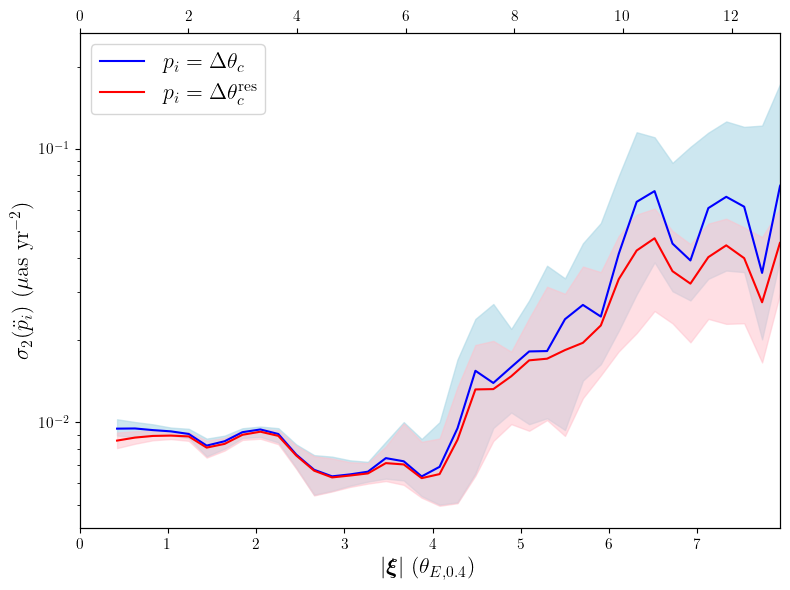

In [48]:
s_to_yr = 1 / (365.25 * 86400)

fig, ax = plt.subplots(figsize=(8,6))  
p16 = acc_sigma_min_16 * rad_to_arcsec / s_to_yr**2
p50 = acc_sigma_min_50 * rad_to_arcsec / s_to_yr**2
p84 = acc_sigma_min_84 * rad_to_arcsec / s_to_yr**2

ax.plot(impact_params / theta_E_4, p50, color='blue',
        label=r'$p_i= \Delta \theta_c$')
ax.fill_between(impact_params / theta_E_4, p16, p84, alpha=0.6, color='lightblue')

# --- residual, min-eigenvalue version ---
# mag_acc_sig_r_min should be built the same way mag_acc_sig_r currently is,
# but from acc_sigma_min_res2 instead of the quadrature-norm quantity
p16 = np.nanpercentile(acc_sigma_min_res2, 16, axis=-1) * rad_to_arcsec / s_to_yr**2
p50 = np.nanpercentile(acc_sigma_min_res2, 50, axis=-1) * rad_to_arcsec / s_to_yr**2
p84 = np.nanpercentile(acc_sigma_min_res2, 84, axis=-1) * rad_to_arcsec / s_to_yr**2

ax.plot(impact_params / theta_E_4, p50, color='red',
        label=r'$p_i= \Delta \theta_c^\text{res}$')
ax.fill_between(impact_params / theta_E_4, p16, p84, alpha=0.5, color='pink')

ax_top = ax.twiny()
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)', fontsize=14, labelpad=10)
ax_top.set_xlim(0, xlim*theta_E_4*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\theta_{E, 0.4}$)', fontsize=16)
ax.set_ylabel(r"$\sigma_2(\ddot{p}_i)$ ($\mu$as yr$^{-2}$)", fontsize=16)
ax.set_xlim(0, xlim)
ax.set_yscale('log')

ax.legend(fontsize=16)
fig.tight_layout()

plt.savefig('figures/thetac_acc2_04.pdf')

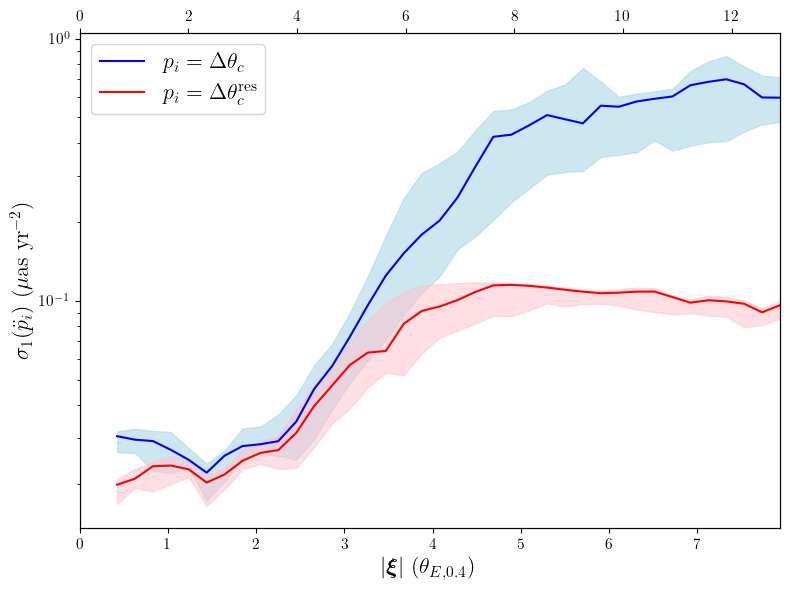

In [49]:

s_to_yr = 1 / (365.25 * 86400)  
p16 = acc_sigma_16* rad_to_arcsec / s_to_yr**2
p84= acc_sigma_84* rad_to_arcsec / s_to_yr**2

fig,ax = plt.subplots(figsize=(8,6))
ylim=.3
ax.plot(impact_params / theta_E_4, acc_sigma_50*rad_to_arcsec/s_to_yr**2, color='blue', 
         label=r'$p_i= \Delta \theta_c$')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.6, color='lightblue')


p16 = np.nanpercentile(mag_acc_sig_r, 16, axis=-1)* rad_to_arcsec / s_to_yr**2
p84=  np.nanpercentile(mag_acc_sig_r, 84, axis=-1)* rad_to_arcsec / s_to_yr**2
ax.plot(impact_params / theta_E_4, acc_sigma_res_50*rad_to_arcsec / s_to_yr**2, color='red',
    label=r'$p_i= \Delta \theta_c^\text{res}$')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.5, color='pink')


#ticks_top=np.linspace(theta_E_4[0]*rad_to_arcsec, np.round(xlim)*theta_E_4[0]*rad_to_arcsec, 6) 

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\mu$as)',  fontsize=16, labelpad=10)
ax_top.set_xlim(0, xlim*theta_E_4*rad_to_arcsec)

#ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\theta_{E, 0.4}$)', fontsize=16)
ax.set_ylabel(r"$\sigma_1(\ddot{p}_i)$ ($\mu$as yr$^{-2}$)", fontsize=16)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.set_yscale('log')

ax.legend(fontsize=16)
fig.tight_layout()

plt.savefig('figures/thetac_acc_04.pdf')

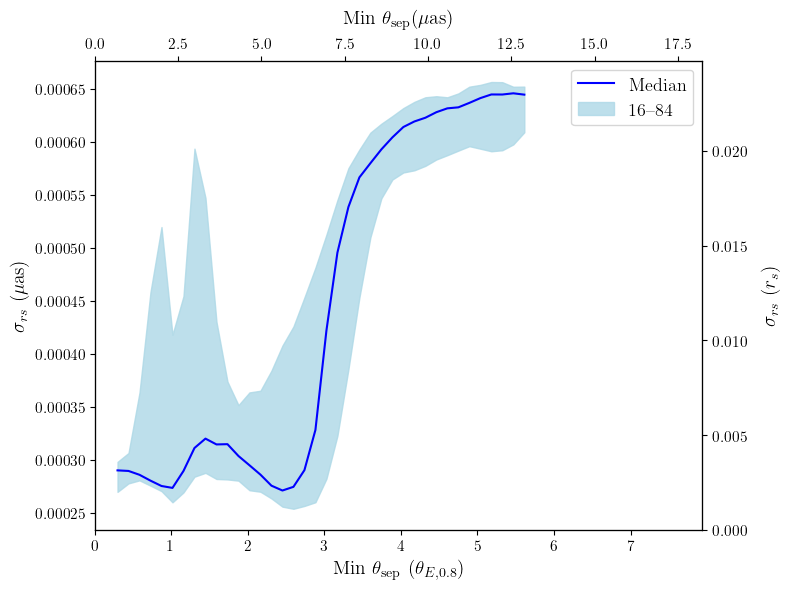

In [91]:
p16 = np.array(np.percentile(uncert_full[:,:,0], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,0], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6))
ylim=.001
ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,0], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ticks_top=np.linspace(theta_E_8*rad_to_arcsec, 8*theta_E_8*rad_to_arcsec, 6) 

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
ax_right.set_ylabel(r'$\sigma_{rs}$ ($r_s$)',  fontsize=14, labelpad=10)
ax_right.set_ylim(0,ylim/rad_mas)

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14);
ax.set_ylabel(r"$\sigma_{rs}$ ($\mu$as)",  fontsize=14)
ax.set_xlim(0, xlim)
#ax.set_ylim(.0004, ylim)

ax.legend(fontsize=13)
fig.tight_layout()
plt.savefig('figures/rad_traj_04.pdf')

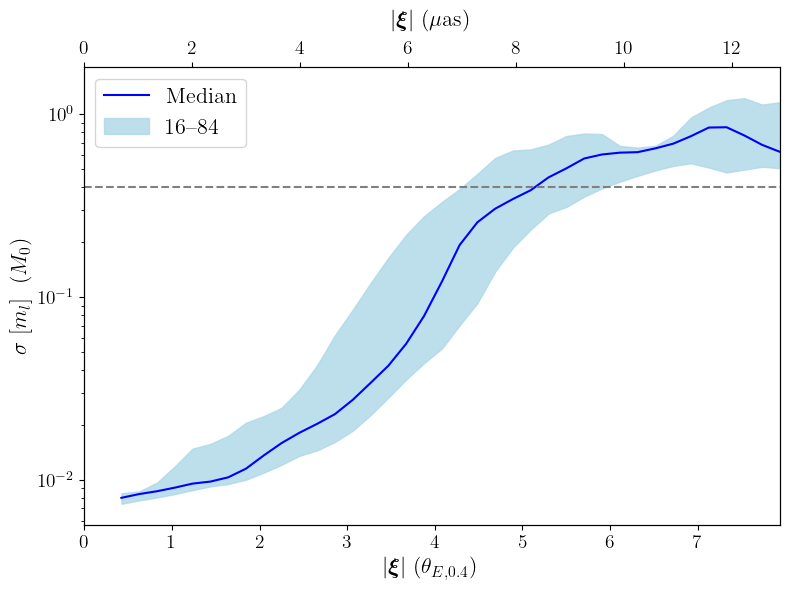

In [50]:
p16 = np.array(np.percentile(uncert_full[:,:,1], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,1], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6))
ax.plot(impact_params / theta_E_4, np.percentile(uncert_full[:,:,1], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\mu$as)',  fontsize=16, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_4*rad_to_arcsec)
ax.axhline(0.4, linestyle='dashed', color='gray')


ax_top.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='major', labelsize=14)

ax.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\theta_{E, 0.4}$)', fontsize=16)
ax.set_ylabel(r"$\sigma \ [m_l]\ \ (M_0)$", fontsize=16)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, .55)
ax.set_yscale('log')

ax.legend(fontsize=16)
fig.tight_layout()
plt.savefig('figures/mass_traj_04.pdf')

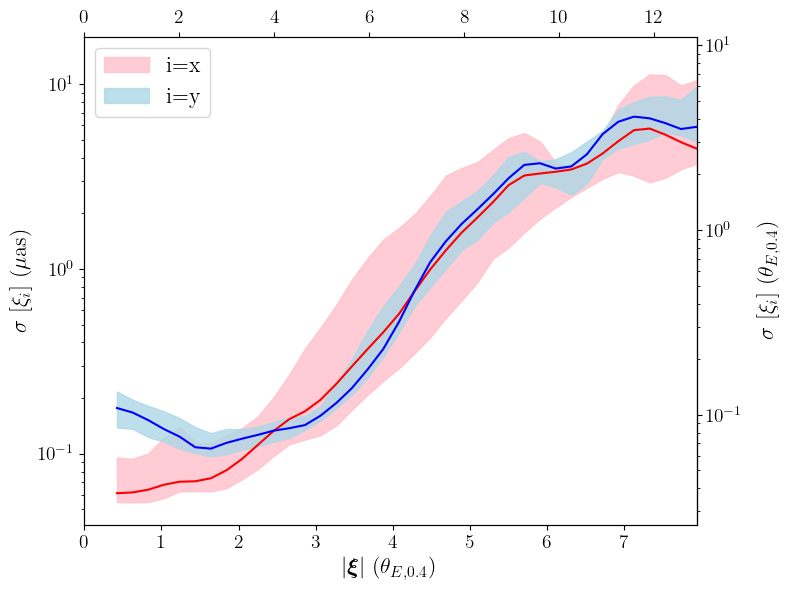

In [51]:
p16 = np.array(np.percentile(uncert_full[:,:,2], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,2], 84, axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(8,6))

p16_y = np.array(np.percentile(uncert_full[:,:,3], 16, axis=1), dtype=float)
p84_y = np.array(np.percentile(uncert_full[:,:,3], 84, axis=1), dtype=float)

ax.plot(impact_params / theta_E_4, np.percentile(uncert_full[:,:,2], 50, axis=1), color='red')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.8, label='i=x', color='pink')

ax.plot(impact_params / theta_E_4, np.percentile(uncert_full[:,:,3], 50, axis=1), color='blue')
ax.fill_between(impact_params / theta_E_4, p16_y, p84_y,  alpha=0.8, label='i=y', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
#ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_4*rad_to_arcsec)

ylim=7

ax_top.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='major', labelsize=14)

ax.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\theta_{E, 0.4}$)', fontsize=16)
ax.set_ylabel(r"$\sigma \ [\xi_i]$ ($\mu$as)", fontsize=16)
ax.legend()
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.set_yscale('log')

# secondary y-axis in units of theta_{E,0.4}; secondary_yaxis tracks the log scale so ticks stay aligned
conv = float(np.ravel(rad_to_arcsec*theta_E_4)[0])  # muas per theta_{E,0.4}
ax_right = ax.secondary_yaxis('right', functions=(lambda v: v/conv, lambda v: v*conv))
ax_right.set_ylabel(r'$\sigma \ [\xi_i]$  ($\theta_{E, 0.4}$)', fontsize=16, labelpad=10)
ax_right.tick_params(axis='both', which='major', labelsize=14)

ax.legend(fontsize=16, loc='upper left')
fig.tight_layout()


plt.savefig('figures/pos_traj_04.pdf')



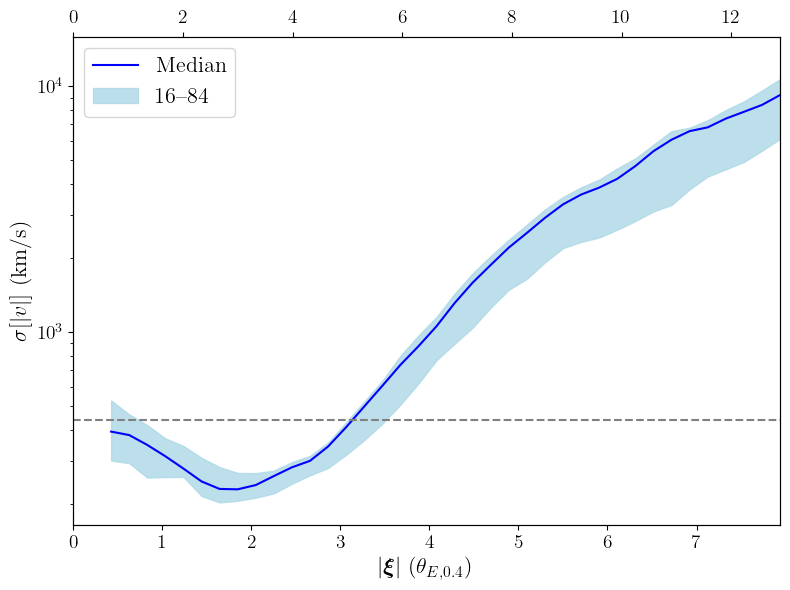

In [52]:
xvels=np.array(uncert_full[:,:,4])
yvels=np.array(uncert_full[:,:,5])
vels=np.array(xvels**2+yvels**2)**(.5)
p16 = (np.array(np.percentile(vels, 16, axis=1), dtype=float))
p84 =  (np.array(np.percentile(vels, 84, axis=1), dtype=float))
p5 = (np.array(np.percentile(vels, 0, axis=1), dtype=float))
p95 =  (np.array(np.percentile(vels, 100, axis=1), dtype=float))

p50=(np.array(np.percentile(vels, 50, axis=1), dtype=float))
fig,ax = plt.subplots(figsize=(8,6))
ylim=7200


ax.plot(impact_params / theta_E_4, p50 , color='blue', label='Median')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')
#ax.fill_between(impact_params / theta_E_4, p5, p95,  alpha=0.2, label='Full range', color='grey')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
#ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_4*rad_to_arcsec)

ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='major', labelsize=14)

ax.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\theta_{E, 0.4}$)', fontsize=16)
ax.set_ylabel(r"$\sigma [|v|]$ (km/s)", fontsize=16)
#plt.xlim(0.4, 2.5)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.set_yscale('log')

ax.legend(fontsize=16)
fig.tight_layout()

plt.savefig('figures/vel_traj_04.pdf')


In [95]:
xvels=np.array(uncert_full[:,:,4])
yvels=np.array(uncert_full[:,:,5])
vels=np.array(xvels**2+yvels**2)**(.5)
p50=(np.array(np.percentile(vels, 50, axis=1), dtype=float))

vel_true=np.sqrt(bulk_vel**2+vel_disp**2)

In [ ]:
# 2/tau = 4 so we would expect a bit worse here 